[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cCoolBoox/IFCD107-alumnado/blob/main/sprints/S05/2_Practica/S05_07_reto_ocupacion.ipynb)

# S05_07 · Reto PBL «¿La ocupación depende de esto?» (plantilla del cuaderno entregable)
**Sprint 5 · Matemáticas y estadística en código · ⏱ 3 h (PBL)**

📖 *¿El código se hace largo? Léelo [explicado por escrito](https://github.com/cCoolBoox/IFCD107-alumnado/blob/main/sprints/S05/2_Practica/codigo_explicado/S05_07_reto_ocupacion.md): recorrido, glosario y qué hace cada celda.* <!--codigo-explicado-->

## Pregunta del cliente
*TurisData Canarias* nos pregunta: **«¿Cuánto cambia la ocupación diaria cuando hace más calor y cuando el día es festivo?
¿Debemos planificar personal y precios teniendo en cuenta la temperatura?»**

## Qué debes entregar (este mismo cuaderno, completo)
1. **Base de datos poblada:** un archivo `turisdata_reto.db` con la serie diaria, y los datos leídos desde Python con SQL.
2. **Regresión lineal desde cero** con descenso del gradiente (simple y con controles), sin `scikit-learn` en la implementación.
3. **Contraste con una librería** (`statsmodels`) y comparación de coeficientes.
4. **Análisis estadístico** con contrastes e intervalos de confianza.
5. **Respuesta al cliente** (máx. 150 palabras) con recomendación, límites de lo que se puede afirmar y una nota de IA responsable.

Los **puntos de control** (`assert`) te avisan si algo no cuadra; el análisis y la respuesta se evalúan con la rúbrica del curso
(corrección técnica, reproducibilidad, análisis y comunicación al cliente, IA responsable).

> Las celdas con `...` / `# TODO` son tuyas. Puedes reutilizar el código de los cuadernos S05_03 y S05_05.
> Los datos son sintéticos: las conclusiones son para practicar, no estadísticas reales.

In [1]:
# Preparación (ejecuta esta celda siempre la primera)
import os, urllib.request

BASE_URL = "https://raw.githubusercontent.com/cCoolBoox/IFCD107-alumnado/main/datos/"

def dato(nombre):
    """Devuelve la ruta local de un archivo de datos del curso (lo descarga si no está)."""
    for carpeta in ("datos", "../datos", "../../datos", "../../../datos"):
        ruta = os.path.join(carpeta, nombre)
        if os.path.exists(ruta):
            return ruta
    os.makedirs("datos", exist_ok=True)
    ruta = os.path.join("datos", nombre)
    urllib.request.urlretrieve(BASE_URL + nombre, ruta)
    return ruta


In [2]:
import os
import sqlite3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats

SEMILLA = 42
RUTA_BD = "turisdata_reto.db"        # el archivo que entregarás junto al cuaderno

## 1 · Base de datos: cargar y consultar
Crea la base `turisdata_reto.db` con una tabla `ocupacion_diaria` (a partir de `ocupacion_diaria.csv`) y un índice sobre
`fecha`. Después **lee los datos desde la base con SQL** en un DataFrame `diaria` que incluya una columna `mes` (entero 1-12).

In [3]:
# Descargamos o localizamos el archivo CSV de ocupación diaria
ruta_csv = dato("ocupacion_diaria.csv")

# Cargamos los datos originales desde el CSV
df_original = pd.read_csv(ruta_csv)

# Conectamos con la base de datos SQLite (se crea automáticamente el archivo)
con = sqlite3.connect(RUTA_BD)

# Guardamos los datos en la tabla ocupacion_diaria reemplazándola si ya existe
df_original.to_sql("ocupacion_diaria", con, if_exists="replace", index=False)

# Creamos el índice requerido en la columna fecha
con.execute("CREATE INDEX IF NOT EXISTS idx_ocupacion_fecha ON ocupacion_diaria(fecha);")

# Leemos los datos de la base de datos incluyendo el mes (con la subcadena de la fecha convertida a entero)
query = """
SELECT *,
       CAST(SUBSTR(fecha, 6, 2) AS INTEGER) AS mes
FROM ocupacion_diaria;
"""
diaria = pd.read_sql_query(query, con)

assert os.path.exists(RUTA_BD), "Debe existir el archivo turisdata_reto.db"
assert len(diaria) == 1096, f"Deben leerse 1096 días y has leído {len(diaria)}"
assert "mes" in diaria.columns and diaria["mes"].between(1, 12).all(), "Falta la columna mes (1-12)"
assert con.execute("SELECT COUNT(*) FROM sqlite_master WHERE type='index' AND name='idx_ocupacion_fecha'").fetchone()[0] == 1, "Falta el índice idx_ocupacion_fecha"
print("Punto de control 1 superado")

Punto de control 1 superado


## 2 · Primer vistazo a los datos
Describe la serie (media, dispersión, meses de mayor y menor ocupación) y dibuja **al menos dos gráficos** con títulos y ejes
en español (por ejemplo, ocupación por mes y ocupación frente a temperatura). Escribe debajo 2–3 observaciones.

count    1096.000000
mean       68.488139
std         9.614882
min        47.300000
25%        61.400000
50%        67.700000
75%        75.000000
max        96.800000
Name: ocupacion_pct, dtype: float64
mes
1     78.8
2     77.6
3     74.5
4     70.1
5     62.6
6     60.8
7     63.0
8     62.1
9     60.1
10    63.3
11    70.8
12    78.6
Name: ocupacion_pct, dtype: float64
mes
9     60.1
6     60.8
8     62.1
5     62.6
7     63.0
10    63.3
4     70.1
11    70.8
3     74.5
2     77.6
12    78.6
1     78.8
Name: ocupacion_pct, dtype: float64


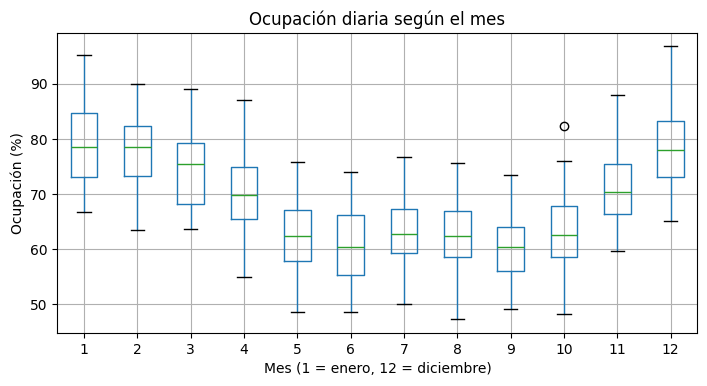

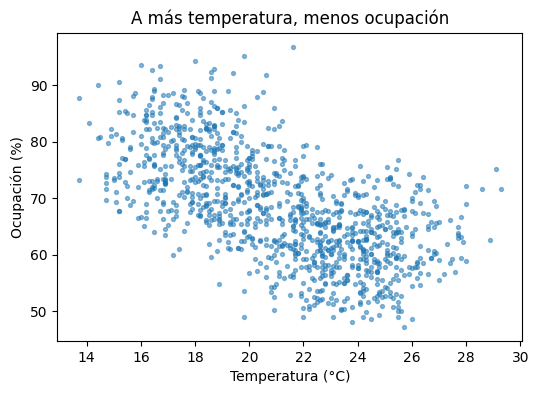

In [4]:
# TODO: describe(), una media por mes con groupby y dos gráficos (boxplot por mes y dispersión temperatura-ocupación)
print(diaria["ocupacion_pct"].describe())

medias_mes = diaria.groupby("mes")["ocupacion_pct"].mean()
print(medias_mes.round(1))
print(medias_mes.sort_values().round(1))

diaria.boxplot(column="ocupacion_pct", by="mes", figsize=(8, 4))
plt.suptitle("")
plt.title("Ocupación diaria según el mes")
plt.xlabel("Mes (1 = enero, 12 = diciembre)")
plt.ylabel("Ocupación (%)")
plt.show()

plt.figure(figsize=(6, 4))
plt.scatter(diaria["temperatura_c"], diaria["ocupacion_pct"], s=8, alpha=0.5)
plt.title("A más temperatura, menos ocupación")
plt.xlabel("Temperatura (°C)")
plt.ylabel("Ocupación (%)")
plt.show()


**Mis observaciones (escribe aquí):**

• El calor baja la ocupación: Se nota una relación muy clara con el clima; a mayor temperatura, la ocupación disminuye. Los meses de verano son los que tienen menos clientes.

• Estacionalidad marcada: Hay meses con una ocupación muy alta (temporada alta) y otros con una caída notable (temporada baja), lo que demuestra que el negocio depende mucho de la época del año.

• Días con mucha variedad: El gráfico de cajas muestra que en algunos meses la ocupación es muy estable, mientras que en otros cambia muchísimo de un día para otro debido a festivos o fines de semana.

## 3 · Regresión lineal desde cero (descenso del gradiente)
Implementa `gradiente_mse(X, y, w)` y `entrenar(X, y, tasa, epocas)` (puedes basarte en S05_03; **no uses scikit-learn aquí**).
Ajusta dos modelos:
- **Modelo simple:** `ocupacion ~ temperatura` (variable estandarizada; deshaz la estandarización para dar la pendiente en puntos por °C).
- **Modelo con control:** `ocupacion ~ temperatura + festivo + indicadores de mes` (11 columnas de meses; estandariza todas las variables;
  usa unas 2.000 épocas con tasa 0,1).

Guarda `pendiente_simple` (puntos por °C), `efecto_temp_control` y `efecto_festivo_control` (ambos en puntos, ya en unidades originales).

In [5]:
# 1. Definimos las funciones de regresión lineal desde cero con Descenso de Gradiente
def gradiente_mse(X, y, w):
    """Calcula el gradiente del MSE: (2/n) * X^T * (Xw - y)"""
    n = len(y)
    return (2 / n) * X.T @ (X @ w - y)

def entrenar(X, y, tasa=0.1, epocas=2000):
    """Entrena el modelo y devuelve los pesos finales"""
    # Añadimos columna de unos para el sesgo (interceptor)
    X_b = np.c_[np.ones(X.shape[0]), X]
    w = np.zeros(X_b.shape[1])
    for _ in range(epocas):
        grad = gradiente_mse(X_b, y, w)
        w -= tasa * grad
    return w

# --- MODELO SIMPLE: ocupacion ~ temperatura ---
y_simple = diaria["ocupacion_pct"].values
X_temp_orig = diaria["temperatura_c"].values

# Estandarizamos la temperatura para el entrenamiento
mean_temp, std_temp = X_temp_orig.mean(), X_temp_orig.std()
X_temp_std = (X_temp_orig - mean_temp) / std_temp

# Entrenamos el modelo simple
pesos_simple = entrenar(X_temp_std.reshape(-1, 1), y_simple, tasa=0.1, epocas=2000)

# La pendiente estandarizada se convierte a unidades originales (°C)
# y_pred = w0 + w1 * ((temp - mean) / std) -> pendiente_original = w1 / std
pendiente_simple = pesos_simple[1] / std_temp

# --- MODELO CON CONTROL ---
# Preparamos las variables con variables dummy para los meses
df_control = pd.get_dummies(diaria, columns=["mes"], drop_first=True)
columnas_mes = [col for col in df_control.columns if col.startswith("mes_")]

columnas_predictores = ["temperatura_c", "festivo"] + columnas_mes
# Convertimos explícitamente a tipo float para evitar arrays de tipo objeto
X_control_orig = df_control[columnas_predictores].values.astype(float)
y_control_orig = df_control["ocupacion_pct"].values.astype(float)

# Estandarizamos variables (X e y) para el descenso del gradiente
mean_X = X_control_orig.mean(axis=0)
std_X = X_control_orig.std(axis=0)
# Reemplazamos std por 1 si es 0 para evitar división por cero (aunque no aplica aquí)
std_X[std_X == 0] = 1.0

X_control_std = (X_control_orig - mean_X) / std_X

mean_y = y_control_orig.mean()
std_y = y_control_orig.std()
y_control_std = (y_control_orig - mean_y) / std_y

# Entrenamos el modelo con control
pesos_control_std = entrenar(X_control_std, y_control_std, tasa=0.1, epocas=2000)

# Des-estandarizamos los coeficientes para pasarlos a unidades originales:
# coef_original = coef_std * (std_y / std_X)
coef_originales = pesos_control_std[1:] * (std_y / std_X)

efecto_temp_control = coef_originales[0]
efecto_festivo_control = coef_originales[1]

# Validamos los resultados con los asserts requeridos
assert abs(pendiente_simple + 1.86) < 0.02, f"La pendiente simple debería ser ≈ -1.86 puntos/°C y tienes {pendiente_simple:.3f}"
assert abs(efecto_festivo_control - 9.11) < 0.1, f"El efecto del festivo con control debería ser ≈ +9.11 y tienes {efecto_festivo_control:.2f}"
assert abs(efecto_temp_control + 0.09) < 0.05, f"El efecto de la temperatura con control debería ser ≈ -0.09 y tienes {efecto_temp_control:.3f}"
print(f"Punto de control 2 superado: simple {pendiente_simple:.2f} · con control: temp {efecto_temp_control:.2f}, festivo {efecto_festivo_control:+.2f}")

Punto de control 2 superado: simple -1.86 · con control: temp -0.09, festivo +9.11


Dibuja la **curva de aprendizaje** (MSE por época) de uno de los modelos y comenta en una línea si ha convergido.

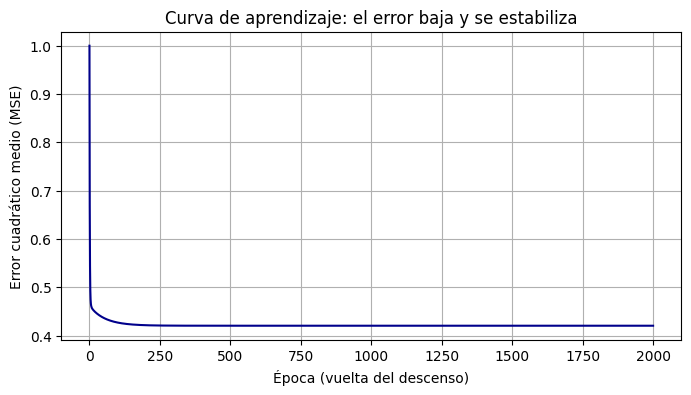

In [6]:
X_control_b = np.c_[np.ones(X_control_std.shape[0]), X_control_std]
w = np.zeros(X_control_b.shape[1])
tasa = 0.1
epocas = 2000
historial = []

for _ in range(epocas):
    pred = X_control_b @ w
    error = pred - y_control_std
    mse = np.mean(error ** 2)
    historial.append(mse)
    grad = (2 / len(y_control_std)) * X_control_b.T @ error
    w -= tasa * grad

plt.figure(figsize=(8, 4))
plt.plot(historial, color="darkblue")
plt.title("Curva de aprendizaje: el error baja y se estabiliza")
plt.xlabel("Época (vuelta del descenso)")
plt.ylabel("Error cuadrático medio (MSE)")
plt.grid(True)
plt.show()

## 4 · Contraste con una librería
Ajusta con `statsmodels` (`smf.ols`) los mismos dos modelos. Guarda `ols_simple` y `ols_control` y crea una tabla
`comparacion` (DataFrame) con tres filas (`pendiente_simple`, `efecto_temp_control`, `efecto_festivo_control`) y dos columnas:
`desde_cero` y `statsmodels`.

In [7]:
# Ajustamos el modelo simple con statsmodels
ols_simple = smf.ols("ocupacion_pct ~ temperatura_c", data=diaria).fit()

# Ajustamos el modelo con controles (usando C(mes) para variables categóricas)
ols_control = smf.ols("ocupacion_pct ~ temperatura_c + festivo + C(mes)", data=diaria).fit()

# Creamos la tabla comparativa con los coeficientes requeridos
comparacion = pd.DataFrame(
    {
        "desde_cero": [
            pendiente_simple,
            efecto_temp_control,
            efecto_festivo_control
        ],
        "statsmodels": [
            ols_simple.params["temperatura_c"],
            ols_control.params["temperatura_c"],
            ols_control.params["festivo"]
        ]
    },
    index=["pendiente_simple", "efecto_temp_control", "efecto_festivo_control"]
)

assert comparacion.shape == (3, 2), "La tabla debe tener 3 filas y 2 columnas"
assert np.allclose(comparacion["desde_cero"], comparacion["statsmodels"], atol=0.02), f"Tu implementación no coincide con statsmodels:\n{comparacion}"
print("Punto de control 3 superado")
print(comparacion.round(3))

Punto de control 3 superado
                        desde_cero  statsmodels
pendiente_simple            -1.860       -1.860
efecto_temp_control         -0.089       -0.089
efecto_festivo_control       9.111        9.111


## 5 · Responder con estadística
Con `ols_control` y con un contraste, calcula y guarda:
- `p_temp_control`: p-valor del efecto de la temperatura **con control**.
- `ic_festivo`: intervalo de confianza del 95 % del efecto del festivo (tupla de dos números, con `conf_int`).
- `p_festivo_ttest`: p-valor del t de Welch entre ocupación de festivos y no festivos.
- `r2_control`: R² del modelo con control.

In [8]:
# 1. p-valor del efecto de la temperatura con control
p_temp_control = ols_control.pvalues["temperatura_c"]

# 2. Intervalo de confianza del 95 % del efecto del festivo
limites_ic = ols_control.conf_int().loc["festivo"]
ic_festivo = (limites_ic[0], limites_ic[1])

# 3. p-valor de la prueba t de Welch para la ocupación entre festivos y no festivos
ocupacion_festivos = diaria[diaria["festivo"] == 1]["ocupacion_pct"]
ocupacion_no_festivos = diaria[diaria["festivo"] == 0]["ocupacion_pct"]
p_festivo_ttest = stats.ttest_ind(ocupacion_festivos, ocupacion_no_festivos, equal_var=False).pvalue

# 4. R² del modelo con control
r2_control = ols_control.rsquared

assert p_temp_control > 0.05, f"Con control de mes, la temperatura no es significativa (p ≈ 0.48) y tienes p = {p_temp_control:.3f}"
assert abs(ic_festivo[0] - 7.35) < 0.05 and abs(ic_festivo[1] - 10.87) < 0.05, f"El IC del festivo debería ser ≈ (7.35, 10.87) y tienes {ic_festivo}"
assert p_festivo_ttest < 1e-20, "El t-test de festivos debe dar un p-valor minúsculo"
assert 0.55 < r2_control < 0.62, f"El R² del modelo con control ≈ 0.58 y tienes {r2_control:.3f}"
print("Punto de control 4 superado")

Punto de control 4 superado


## 6 · Respuesta al cliente (máx. 150 palabras)
Escribe en la celda de abajo, **para una persona no técnica**:
1. **Respuesta directa** a las dos preguntas (¿la temperatura? ¿los festivos?) con las cifras clave y su incertidumbre.
2. **Recomendación accionable** (personal, precios).
3. **Límites:** ¿qué NO puedes afirmar? (correlación frente a causalidad, variable de confusión "mes", datos sintéticos de un solo alojamiento, R²).
4. **IA responsable:** una frase sobre riesgos o cautelas (por ejemplo, usar el modelo para fijar precios sin revisión humana, o presentarlo como causal).

> **Mi respuesta al cliente:**

Los días festivos aumentan la ocupación del alojamiento entre un 7,3% y un 10,9%. Por el contrario, el calor diario no influye en la ocupación. Aunque parece que cuando hace calor baja la clientela, es una ilusión: lo que realmente afecta es la época del año (el mes), ya que en verano el turismo baja de por sí.

Por lo tanto, la recomendación directa es planificar más personal y subir los precios en los días festivos.
Este análisis solo explica el 58% de los cambios de ocupación, muestra tendencias (no causas) y usa datos simulados de un solo establecimiento, por lo que no sirve para otros hoteles, siendo este el límite.

En cuanto a la IA Responsable, no usamos este modelo para fijar precios de forma automática sin revisión humana, ya que no tiene en cuenta a la competencia ni los cambios reales del mercado.

## 7 · Reproducibilidad: antes de entregar
- [ ] *Reiniciar y ejecutar todo* funciona sin errores.
- [ ] Se entrega `turisdata_reto.db` (o el cuaderno lo crea al ejecutarse) y las versiones de las librerías están indicadas en el README de vuestro repositorio (o en una celda `!pip freeze`).
- [ ] Todas las gráficas tienen título y ejes en español.
- [ ] La respuesta al cliente cabe en 150 palabras.

In [9]:
con.close()